"""
@utor: Yuri Idalgo de Matos da Silva
criação: 27/10/2026
atualização: 27/10/2026 
descrição:
"""

In [1]:
# Importando bibliotecas

import pandas as pd
import geopandas as gpd
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

In [2]:
# Lendo os dados do arquivo JSON

path = Path("C:/Users/x432601/Documents/GitHub/ETL_wifi_livre_2026/data/data_wifi_livre/equipamento_praca_wifi.geojson")
gdf_wifi_livre = gpd.read_file(path)

In [3]:
gdf_wifi_livre.head()

,id,cd_identificador,cd_identificador_tema_equipamento,nm_tema_equipamento,cd_identificador_rede_equipamento,nm_rede_equipamento,tx_rede_equipamento,cd_identificador_tipo_equipamento,nm_tipo_equipamento,tx_tipo_equipamento,...,tx_esfera_administrativa_equipamento,cd_equipamento,nm_equipamento,tx_endereco_equipamento,nm_bairro_equipamento,cd_cep_equipamento,tx_horario_funcionamento,tx_numero_telefone,cd_equipamento_base_origem,geometry
0,equipamento_praca_wifi.172597,172597,8,SERVICO,0,SEM REDE,Sem descrição,0,SEM TIPO,SEM TIPO,...,Sem descrição,None,Escola,"RUA TAQUARI, 459",None,None,,156,None,POINT (336791.861 7394552.421)
1,equipamento_praca_wifi.172017,172017,8,SERVICO,0,SEM REDE,Sem descrição,0,SEM TIPO,SEM TIPO,...,Sem descrição,None,Abrigo de ônibus,"Rua Sena Madureira, 442",None,None,,156,None,POINT (332614.552 7389818.07)
2,equipamento_praca_wifi.172822,172822,8,SERVICO,0,SEM REDE,Sem descrição,0,SEM TIPO,SEM TIPO,...,Sem descrição,None,Escola,"RUA BELÉM, s/n",None,None,,156,None,POINT (337032.992 7395861.899)
3,equipamento_praca_wifi.172016,172016,8,SERVICO,0,SEM REDE,Sem descrição,0,SEM TIPO,SEM TIPO,...,Sem descrição,None,Abrigo de ônibus,"Avenida Republica do Libano, 171",None,None,,156,None,POINT (330273.466 7391062.137)
4,equipamento_praca_wifi.172001,172001,8,SERVICO,0,SEM REDE,Sem descrição,0,SEM TIPO,SEM TIPO,...,Sem descrição,None,Abrigo de ônibus,"Avenida Treze de Maio, 1434",None,None,,156,None,POINT (332101.955 7392875.203)


In [4]:
# Verificando as colunas do GeoDataFrame

print(gdf_wifi_livre.columns.to_list())

['id', 'cd_identificador', 'cd_identificador_tema_equipamento', 'nm_tema_equipamento', 'cd_identificador_rede_equipamento', 'nm_rede_equipamento', 'tx_rede_equipamento', 'cd_identificador_tipo_equipamento', 'nm_tipo_equipamento', 'tx_tipo_equipamento', 'cd_identificador_classe_equipamento', 'nm_classe_equipamento', 'tx_classe_equipamento', 'cd_identificador_esfera_administrativa_equipamento', 'nm_esfera_administrativa_equipamento', 'tx_esfera_administrativa_equipamento', 'cd_equipamento', 'nm_equipamento', 'tx_endereco_equipamento', 'nm_bairro_equipamento', 'cd_cep_equipamento', 'tx_horario_funcionamento', 'tx_numero_telefone', 'cd_equipamento_base_origem', 'geometry']


In [5]:
# Verificando o tipo de geometria

print(gdf_wifi_livre.geom_type.unique())

<StringArray>
['Point']
Length: 1, dtype: str


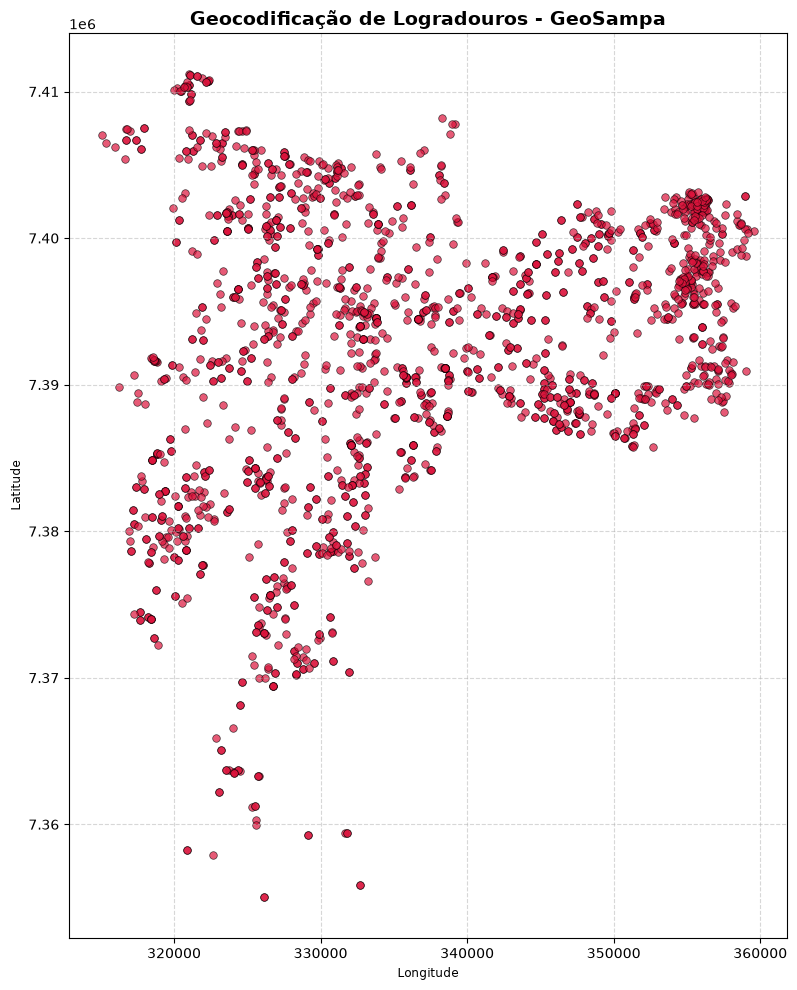

In [10]:
# Teste 1: Visualização estática com Matplotlib

# 1. Carregar o arquivo GeoJSON
gdf = gpd.read_file(path)

# 2. Configurar a figura
fig, ax = plt.subplots(figsize=(10, 10))

# 3. Plotar os dados
# Se tiver pontos:
gdf.plot(
    ax=ax,
    color="crimson",
    markersize=30,
    alpha=0.7,
    edgecolor="black",
    linewidth=0.5
)

# 4. Ajustes visuais
ax.set_title("Geocodificação de Logradouros - GeoSampa", fontsize=14, fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [12]:
# Teste

# 1. Carregar o GeoJSON
gdf = gpd.read_file(path)

# 2. Criar visualização interativa
# O método detecta os pontos e plota sobre o OpenStreetMap
mapa = gdf.explore(
    column="geometry",  # Colore os pontos de acordo com o status (ex: Exato, Fuzzy)
    cmap="Set1",
    marker_kwds={"radius": 6},
    tooltip=["tx_endereco_equipamento", "geometry"],  # Exibe os dados ao passar o mouse
    popup=True,  # Exibe todos os atributos ao clicar no ponto
    tiles="CartoDB positron"  # Fundo claro e limpo para destacar os dados
)

# 3. Salvar como página HTML navegável ou visualizar no Jupyter Notebook
mapa.save("visualizacao_enderecos.html")
print("Mapa interativo salvo em 'visualizacao_enderecos.html'.")

c:\Users\x432601\AppData\Local\anaconda3\envs\wifi_livre_sp\Lib\site-packages\geopandas\explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


TypeError: 'GeometryArray' with dtype geometry does not support operation 'min'

In [13]:
# Teste 3
# 1. Carregar o GeoJSON
gdf = gpd.read_file(path)

# 2. Criar visualização interativa
mapa = gdf.explore(
    color="blue",  # Define uma cor fixa para os pontos
    marker_kwds={"radius": 6},
    tooltip=["nm_equipamento", "tx_endereco_equipamento"],  # Informações ao passar o mouse
    popup=True,  # Exibe todos os atributos ao clicar no ponto
    tiles="CartoDB positron"
)

# 3. Salvar como página HTML
mapa.save("visualizacao_enderecos.html")
print("Mapa interativo salvo em 'visualizacao_enderecos.html'.")

c:\Users\x432601\AppData\Local\anaconda3\envs\wifi_livre_sp\Lib\site-packages\geopandas\explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


Mapa interativo salvo em 'visualizacao_enderecos.html'.


In [14]:
# Teste 4

# 1. Carregar os dados
gdf = gpd.read_file(path)

# Filtrar geometrias nulas ou vazias para evitar erros no renderizador
gdf = gdf[gdf.geometry.notnull() & ~gdf.geometry.is_empty]

# 2. Configurar visualização com Satélite
mapa = gdf.explore(
    column="nm_tipo_equipamento",  # ou color="red" se preferir cor única
    cmap="Set1",
    marker_kwds={"radius": 6},
    tooltip=["nm_equipamento", "tx_endereco_equipamento"],
    popup=True,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery"  # Atribuição obrigatória ao usar URL personalizada
)

# 3. Salvar
mapa.save("visualizacao_enderecos.html")
print("Mapa com satélite salvo com sucesso.")

Mapa com satélite salvo com sucesso.


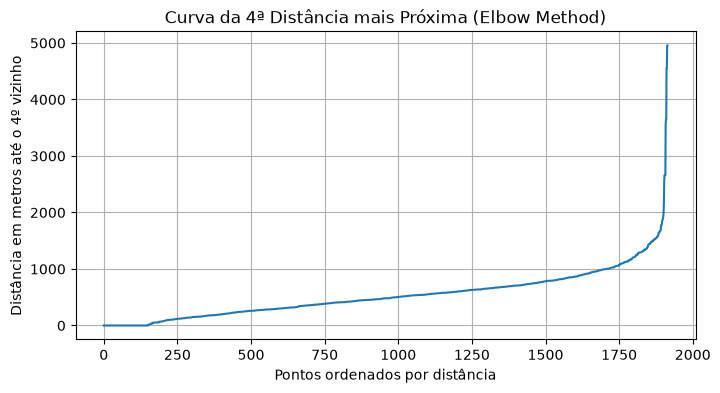

Número de clusters identificados: 125
Pontos isolados / ruído (cluster = -1): 1002
Proporção de pontos isolados: 52.32%

Top 5 maiores clusters por quantidade de pontos:
cluster
80     85
77     47
118    29
30     16
5      16
Name: count, dtype: int64


In [15]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# 1. Extração da matriz de coordenadas métricas (X, Y em metros)
# Certifique-se de que o CRS está métrico (ex: EPSG:31983)
coords = np.column_stack((gdf.geometry.x, gdf.geometry.y))

# --------------------------------------------------------------------
# 2. Diagnóstico do Cotovelo para escolha do eps
# --------------------------------------------------------------------
min_pts = 4  # Regra prática comum para 2D: min_pts >= 2 * dimensoes
vizinhos = NearestNeighbors(n_neighbors=min_pts)
vizinhos_fit = vizinhos.fit(coords)
distancias, _ = vizinhos_fit.kneighbors(coords)

# Ordena as distâncias até o k-ésimo vizinho
k_dist = np.sort(distancias[:, min_pts - 1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.title(f"Curva da {min_pts}ª Distância mais Próxima (Elbow Method)")
plt.xlabel("Pontos ordenados por distância")
plt.ylabel(f"Distância em metros até o {min_pts}º vizinho")
plt.grid(True)
plt.show()

# --------------------------------------------------------------------
# 3. Execução do DBSCAN
# --------------------------------------------------------------------
# Suponha que o cotovelo ou a premissa de caminhabilidade aponte para 400 metros:
raio_eps = 400.0  # metros

db = DBSCAN(eps=raio_eps, min_samples=min_pts, metric="euclidean")
gdf["cluster"] = db.fit_predict(coords)

# --------------------------------------------------------------------
# 4. Avaliação dos Resultados
# --------------------------------------------------------------------
n_clusters = len(set(gdf["cluster"])) - (1 if -1 in gdf["cluster"].values else 0)
n_ruido = (gdf["cluster"] == -1).sum()

print(f"Número de clusters identificados: {n_clusters}")
print(f"Pontos isolados / ruído (cluster = -1): {n_ruido}")
print(f"Proporção de pontos isolados: {n_ruido / len(gdf):.2%}")

# Visualização da distribuição por cluster
print("\nTop 5 maiores clusters por quantidade de pontos:")
print(gdf[gdf["cluster"] != -1]["cluster"].value_counts().head(5))

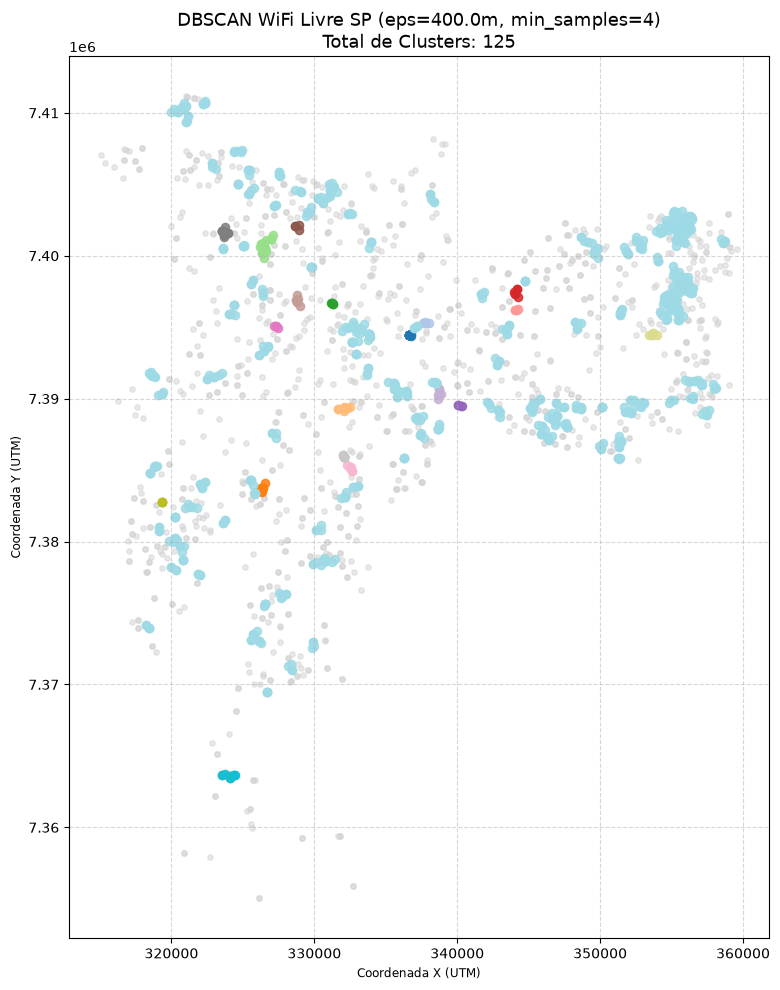

In [18]:
import matplotlib.pyplot as plt

# 1. Separar clusters válidos do ruído
ruido = gdf[gdf["cluster"] == -1]
clusters = gdf[gdf["cluster"] != -1]

fig, ax = plt.subplots(figsize=(10, 10))

# 2. Plotar os pontos de ruído (isolados) em cinza claro e menor tamanho
if not ruido.empty:
    ruido.plot(
        ax=ax,
        color="lightgray",
        markersize=15,
        alpha=0.5,
        label=f"Ruído / Isolados (n={len(ruido)})",
    )

# 3. Plotar os clusters com colormap categórico
if not clusters.empty:
    clusters.plot(
        ax=ax,
        column="cluster",
        categorical=True,
        cmap="tab20",  # Boa paleta discreta com até 20 cores distintas
        markersize=35,
        alpha=0.85,
        legend=False,  # Legenda para dezenas de clusters polui o gráfico
    )

ax.set_title(
    f"DBSCAN WiFi Livre SP (eps={raio_eps}m, min_samples={min_pts})\nTotal de Clusters: {n_clusters}",
    fontsize=13,
)
ax.set_xlabel("Coordenada X (UTM)")
ax.set_ylabel("Coordenada Y (UTM)")
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

C:\Users\x432601\AppData\Local\Temp\ipykernel_5124\1311548719.py:21: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  .apply(lambda geom: geom.unary_union.convex_hull)


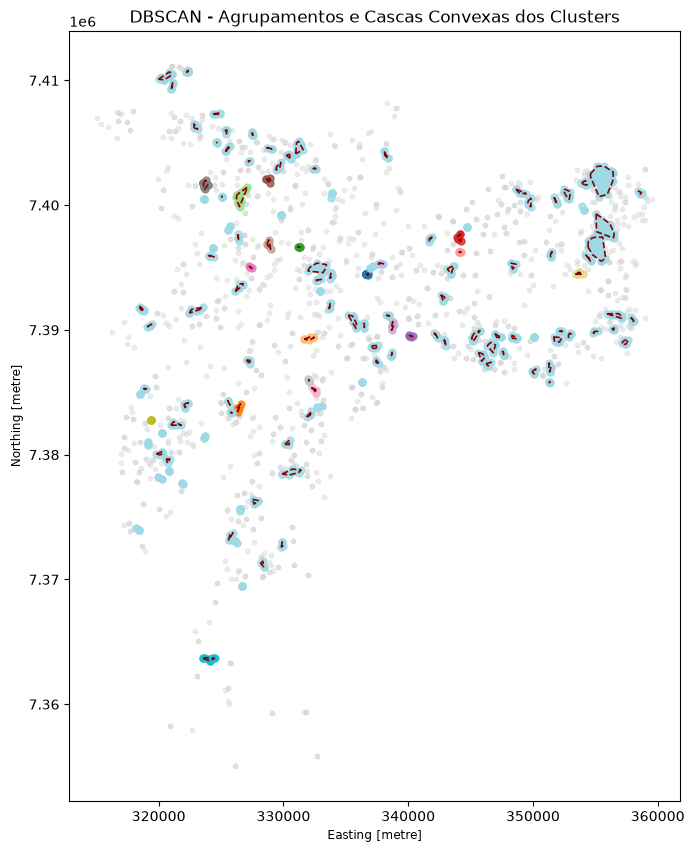

In [19]:
fig, ax = plt.subplots(figsize=(10, 10))

# Plotar o ruído como fundo
gdf[gdf["cluster"] == -1].plot(
    ax=ax, color="lightgray", markersize=10, alpha=0.4, label="Ruído"
)

# Plotar pontos dos clusters
clusters.plot(
    ax=ax,
    column="cluster",
    categorical=True,
    cmap="tab20",
    markersize=25,
    alpha=0.8,
)

# Gerar e plotar os polígonos convexos dos clusters com >= 3 pontos
hulls = (
    clusters.groupby("cluster")["geometry"]
    .apply(lambda geom: geom.unary_union.convex_hull)
    .reset_index()
)
hulls_gdf = gpd.GeoDataFrame(hulls, geometry="geometry", crs=gdf.crs)

# Apenas geometrias poligonais (clusters com pontos alinhados geram LineString)
polygons = hulls_gdf[hulls_gdf.geometry.type == "Polygon"]
polygons.boundary.plot(ax=ax, color="darkred", linewidth=1.2, linestyle="--")

ax.set_title("DBSCAN - Agrupamentos e Cascas Convexas dos Clusters")
ax.set_aspect("equal")
plt.show()

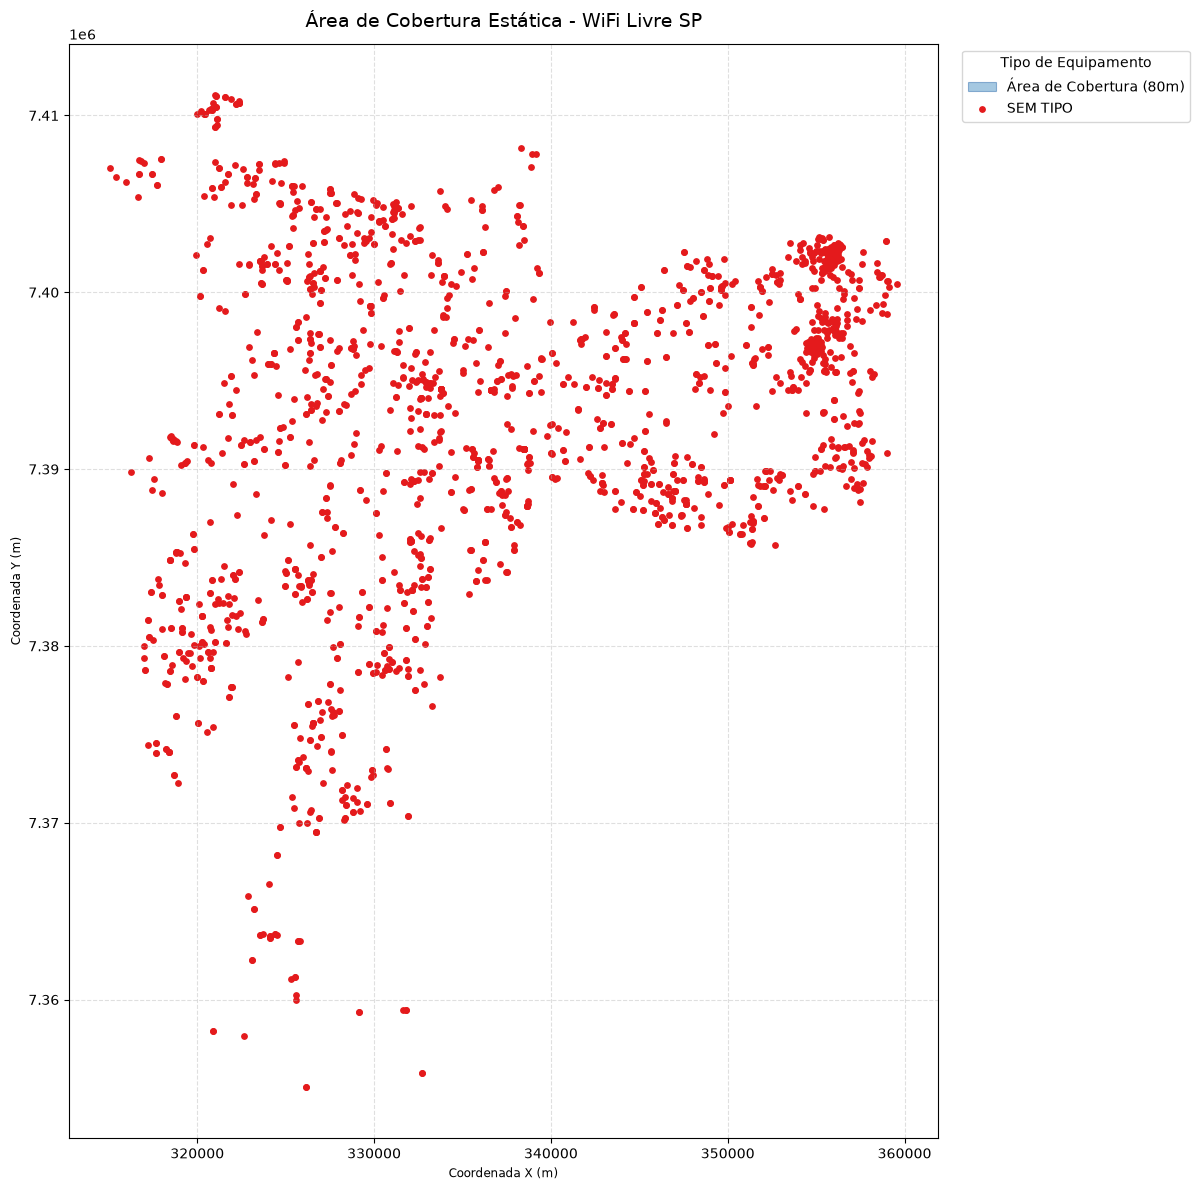

Gráfico estático salvo como area_cobertura_estatica.png


In [21]:
# Teste plot estático com buffer de cobertura
# 1. Carregar os dados e limpar nulos/vazios
gdf = gpd.read_file(path)
gdf = gdf[gdf.geometry.notnull() & ~gdf.geometry.is_empty]

# 2. Garantir CRS projetado em metros (caso esteja em WGS84 / EPSG:4326)
# Se os dados originais já estiverem em UTM (ex: EPSG:31983), confirme ou converta:
if gdf.crs is None:
    gdf = gdf.set_crs(epsg=31983)
elif gdf.crs.is_geographic:
    gdf = gdf.to_crs(epsg=31983)

# 3. Gerar a área de cobertura (buffer de 80 metros, por exemplo)
RAIO_COBERTURA_METROS = 80.0
gdf_cobertura = gdf.copy()
gdf_cobertura["geometry"] = gdf_cobertura.geometry.buffer(RAIO_COBERTURA_METROS)

# Unificar áreas sobrepostas para visualização limpa
cobertura_unificada = gpd.GeoDataFrame(
    geometry=[gdf_cobertura.union_all()], crs=gdf.crs
)

# 4. Configurar e renderizar o plot estático
fig, ax = plt.subplots(figsize=(12, 12))

# Plota a mancha de cobertura em azul claro semitransparente
cobertura_unificada.plot(
    ax=ax,
    facecolor="#1f77b4",
    edgecolor="#08519c",
    alpha=0.4,
    linewidth=0.8,
    label=f"Área de Cobertura ({int(RAIO_COBERTURA_METROS)}m)",
)

# Plota as antenas/pontos por tipo de equipamento
gdf.plot(
    ax=ax,
    column="nm_tipo_equipamento",
    cmap="Set1",
    markersize=15,
    legend=True,
    legend_kwds={"title": "Tipo de Equipamento", "bbox_to_anchor": (1.02, 1), "loc": "upper left"}
)

ax.set_title("Área de Cobertura Estática - WiFi Livre SP", fontsize=14, pad=12)
ax.set_xlabel("Coordenada X (m)")
ax.set_ylabel("Coordenada Y (m)")
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("area_cobertura_estatica.png", dpi=300, bbox_inches="tight")
plt.show()
print("Gráfico estático salvo como area_cobertura_estatica.png")

In [22]:
import geopandas as gpd

# 1. Carregar e limpar dados
gdf = gpd.read_file(path)
gdf = gdf[gdf.geometry.notnull() & ~gdf.geometry.is_empty]

# 2. Assegurar CRS métrico para cálculo exato em metros
if gdf.crs is None:
    gdf = gdf.set_crs(epsg=31983)
elif gdf.crs.is_geographic:
    gdf = gdf.to_crs(epsg=31983)

# 3. Gerar a camada de cobertura (buffers métricos unidos)
RAIO_COBERTURA_METROS = 80.0
gdf_cobertura = gdf.copy()
gdf_cobertura["geometry"] = gdf_cobertura.geometry.buffer(RAIO_COBERTURA_METROS)

# Unificar em polígono contínuo para renderização leve no navegador
cobertura_unificada = gpd.GeoDataFrame(
    geometry=[gdf_cobertura.union_all()], crs=gdf.crs
)

# -------------------------------------------------------------------------
# 4. Construção do Mapa Dinâmico
# -------------------------------------------------------------------------

# Camada 1: Mancha de cobertura (buffers)
mapa = cobertura_unificada.explore(
    color="#1f77b4",
    style_kwds={"fillOpacity": 0.35, "weight": 1, "color": "#08519c"},
    name=f"Área de Cobertura ({int(RAIO_COBERTURA_METROS)}m)",
    tiles="CartoDB positron",  # Fundo urbano limpo e contrastante
)

# Camada 2: Pontos das antenas sobrepostos ao mesmo mapa (m=mapa)
mapa = gdf.explore(
    m=mapa,
    column="nm_tipo_equipamento",
    cmap="Set1",
    marker_type="circle_marker",
    marker_kwds={"radius": 5, "fillOpacity": 0.9, "weight": 0.5},
    tooltip=["nm_equipamento", "nm_tipo_equipamento", "tx_endereco_equipamento"],
    popup=True,
    legend=True,
    name="Pontos de Acesso (WiFi)",
)

# 5. Salvar como HTML interativo
mapa.save("cobertura_dinamica_wifi.html")
print("Mapa interativo salvo com sucesso em cobertura_dinamica_wifi.html")

c:\Users\x432601\AppData\Local\anaconda3\envs\wifi_livre_sp\Lib\site-packages\geopandas\explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")


Mapa interativo salvo com sucesso em cobertura_dinamica_wifi.html


In [23]:
import geopandas as gpd

# 1. Carregar e limpar dados
gdf = gpd.read_file(path)
gdf = gdf[gdf.geometry.notnull() & ~gdf.geometry.is_empty]

# 2. Assegurar CRS métrico para cálculo exato em metros
if gdf.crs is None:
    gdf = gdf.set_crs(epsg=31983)
elif gdf.crs.is_geographic:
    gdf = gdf.to_crs(epsg=31983)

# 3. Gerar a camada de cobertura (buffers métricos unidos)
RAIO_COBERTURA_METROS = 80.0
gdf_cobertura = gdf.copy()
gdf_cobertura["geometry"] = gdf_cobertura.geometry.buffer(RAIO_COBERTURA_METROS)

# Unificar em polígono contínuo para renderização leve no navegador
cobertura_unificada = gpd.GeoDataFrame(
    geometry=[gdf_cobertura.union_all()], crs=gdf.crs
)

# -------------------------------------------------------------------------
# 4. Construção do Mapa Dinâmico com Satélite
# -------------------------------------------------------------------------

# Camada 1: Mancha de cobertura sobre o satélite da Esri
mapa = cobertura_unificada.explore(
    color="#ffff00",  # Amarelo translúcido para alto contraste sobre o satélite
    style_kwds={"fillOpacity": 0.45, "weight": 1.2, "color": "#ffaa00"},
    name=f"Área de Cobertura ({int(RAIO_COBERTURA_METROS)}m)",
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery",
)

# Camada 2: Pontos das antenas sobrepostos ao mesmo mapa (m=mapa)
mapa = gdf.explore(
    m=mapa,
    column="nm_tipo_equipamento",
    cmap="Set1",
    marker_type="circle_marker",
    marker_kwds={"radius": 5, "fillOpacity": 0.95, "weight": 0.8, "color": "white"},
    tooltip=["nm_equipamento", "nm_tipo_equipamento", "tx_endereco_equipamento"],
    popup=True,
    legend=True,
    name="Pontos de Acesso (WiFi)",
)

# 5. Salvar como HTML interativo
mapa.save("cobertura_dinamica_satelite_wifi.html")
print("Mapa interativo com satélite salvo com sucesso em cobertura_dinamica_satelite_wifi.html")

Mapa interativo com satélite salvo com sucesso em cobertura_dinamica_satelite_wifi.html


In [17]:
gdf.head(5)

,id,cd_identificador,cd_identificador_tema_equipamento,nm_tema_equipamento,cd_identificador_rede_equipamento,nm_rede_equipamento,tx_rede_equipamento,cd_identificador_tipo_equipamento,nm_tipo_equipamento,tx_tipo_equipamento,...,cd_equipamento,nm_equipamento,tx_endereco_equipamento,nm_bairro_equipamento,cd_cep_equipamento,tx_horario_funcionamento,tx_numero_telefone,cd_equipamento_base_origem,geometry,cluster
0,equipamento_praca_wifi.172597,172597,8,SERVICO,0,SEM REDE,Sem descrição,0,SEM TIPO,SEM TIPO,...,None,Escola,"RUA TAQUARI, 459",None,None,,156,None,POINT (336791.861 7394552.421),0
1,equipamento_praca_wifi.172017,172017,8,SERVICO,0,SEM REDE,Sem descrição,0,SEM TIPO,SEM TIPO,...,None,Abrigo de ônibus,"Rua Sena Madureira, 442",None,None,,156,None,POINT (332614.552 7389818.07),-1
2,equipamento_praca_wifi.172822,172822,8,SERVICO,0,SEM REDE,Sem descrição,0,SEM TIPO,SEM TIPO,...,None,Escola,"RUA BELÉM, s/n",None,None,,156,None,POINT (337032.992 7395861.899),-1
3,equipamento_praca_wifi.172016,172016,8,SERVICO,0,SEM REDE,Sem descrição,0,SEM TIPO,SEM TIPO,...,None,Abrigo de ônibus,"Avenida Republica do Libano, 171",None,None,,156,None,POINT (330273.466 7391062.137),-1
4,equipamento_praca_wifi.172001,172001,8,SERVICO,0,SEM REDE,Sem descrição,0,SEM TIPO,SEM TIPO,...,None,Abrigo de ônibus,"Avenida Treze de Maio, 1434",None,None,,156,None,POINT (332101.955 7392875.203),-1


In [ ]:
# Suponha 'gdf_distritos' como a malha dos distritos ou setores urbanos de SP
''' # 1. Garantir o mesmo CRS métrico
gdf_distritos = gdf_distritos.to_crs(gdf.crs)

# 2. Calcular a diferença booleana espacial (Malha Urbana MENOS Cobertura das Antenas)
# O resultado são os polígonos que representam o vazio de atendimento
desertos_digitais = gpd.overlay(
    gdf_distritos, cobertura_unificada, how="difference"
)

# 3. Calcular a métrica de desassistência por distrito
gdf_distritos["area_total_km2"] = gdf_distritos.geometry.area / 1e6

# Intersectar os buffers com cada distrito para calcular a porcentagem atendida
cobertura_por_distrito = gpd.overlay(
    gdf_distritos, cobertura_unificada, how="intersection"
)
cobertura_por_distrito["area_atendida_km2"] = (
    cobertura_por_distrito.geometry.area / 1e6
)

# Agrupamento para gerar o indicador de cobertura relativa
atendimento = (
    cobertura_por_distrito.groupby("id_distrito")["area_atendida_km2"]
    .sum()
    .reset_index()
)
resultado = gdf_distritos.merge(atendimento, on="id_distrito", how="left").fillna(0)
resultado["pct_cobertura"] = (
    resultado["area_atendida_km2"] / resultado["area_total_km2"]
) * 100 '''